In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from PortfolioOptimization import get_yearly_report

In [2]:
max_risk = 0.10

In [3]:
from Portfolios.GSPCBuyAndHold import BuyAndHold
from Portfolios.EqualWeights import EqWeightPortfolio
from Portfolios.Markowitz import MarkowitzPortfolio
from Portfolios.MeanAbsDev import MeanAbsDevPortfolio
from Portfolios.MedAbsDev import MedianAbsDevPortfolio

portfolios = {
    'S&P BnH': BuyAndHold,
    'Equal': EqWeightPortfolio,
    'Markowitz': MarkowitzPortfolio,
    'MAD': MeanAbsDevPortfolio,
    'MedAD': MedianAbsDevPortfolio,
}

reports = {}

In [4]:
for name, portfolio in portfolios.items():
    weights, stats = get_yearly_report(portfolio, max_risk)
    reports[name] = {
        'weights': weights,
        'stats': stats
    }
    stats_used = list(stats.columns)
    stats_used.remove('Year')

In [5]:
# Combine Weight files
weights_collector = None
for portfolio, report in reports.items():
    weights = report['weights'].copy()
    weights.columns = ['Year'] \
                        + [(portfolio, column)
                            for column in weights.columns
                            if column != 'Year']
    weights = weights.set_index('Year')

    weights.columns = pd.MultiIndex.from_tuples(weights.columns)
    
    if weights_collector is None:
        weights_collector = weights
    else:
        weights_collector = pd.merge(
                                weights_collector,
                                weights,
                                left_index=True,
                                right_index=True
                            )

weights_collector.to_excel('Output/Weights.xlsx')

In [6]:
# Combine Stats files
stats_collector = None
for portfolio, report in reports.items():
    stats = report['stats'].copy()
    stats.columns = ['Year'] \
                        + [(portfolio, column)
                            for column in stats.columns
                            if column != 'Year']
    stats = stats.set_index('Year')

    stats.columns = pd.MultiIndex.from_tuples(stats.columns)
    
    if stats_collector is None:
        stats_collector = stats
    else:
        stats_collector = pd.merge(
                            stats_collector, 
                            stats, 
                            left_index=True, 
                            right_index=True
                        )

stats_collector.to_excel('Output/Stats.xlsx')

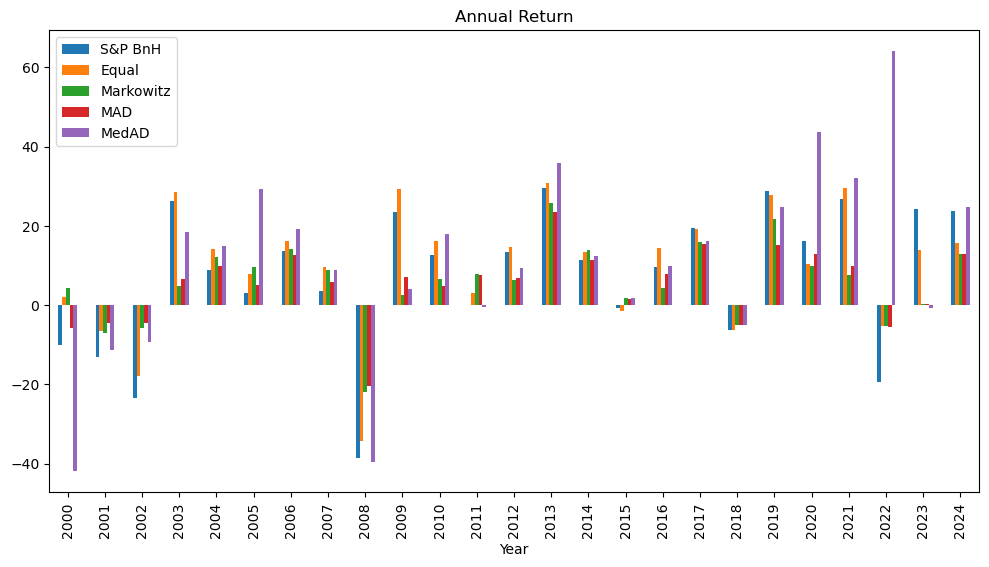

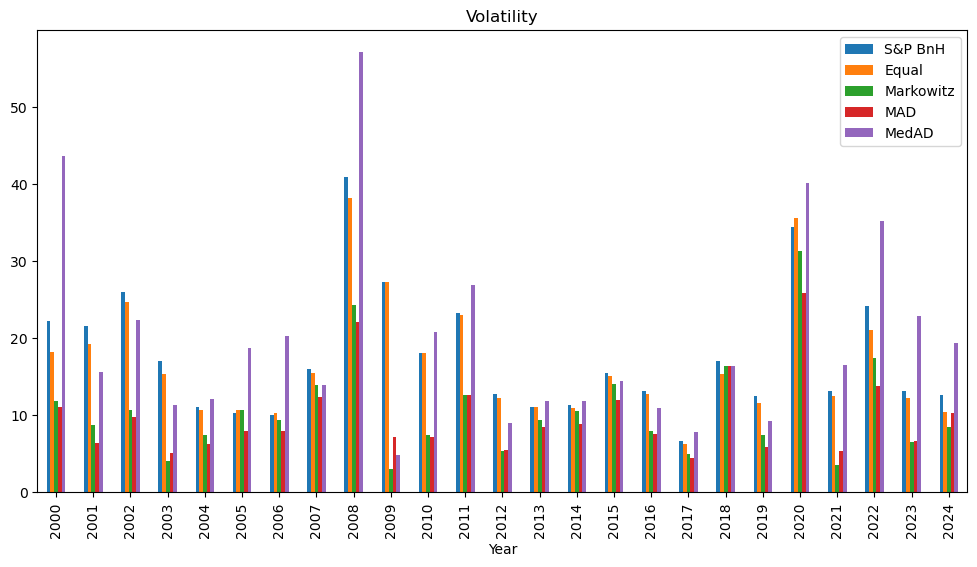

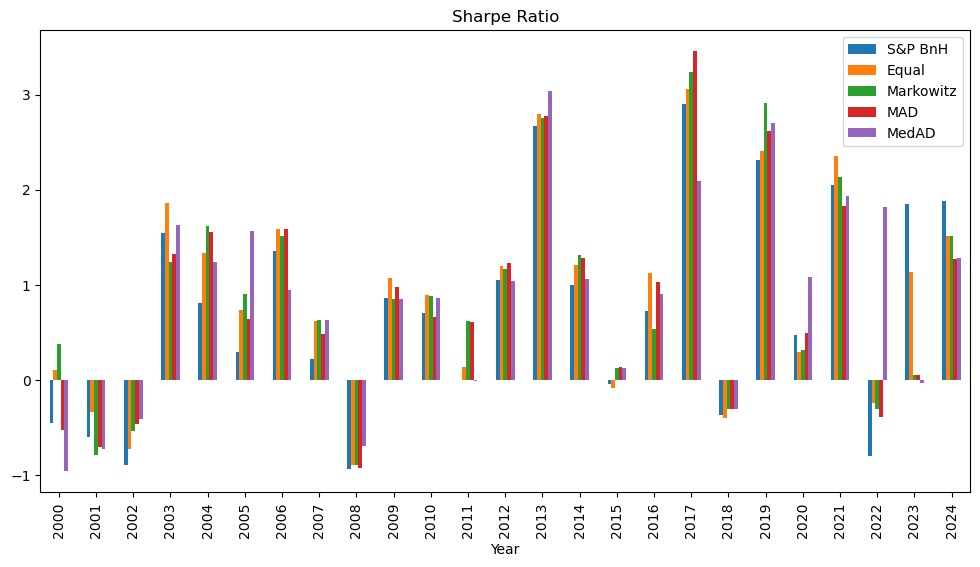

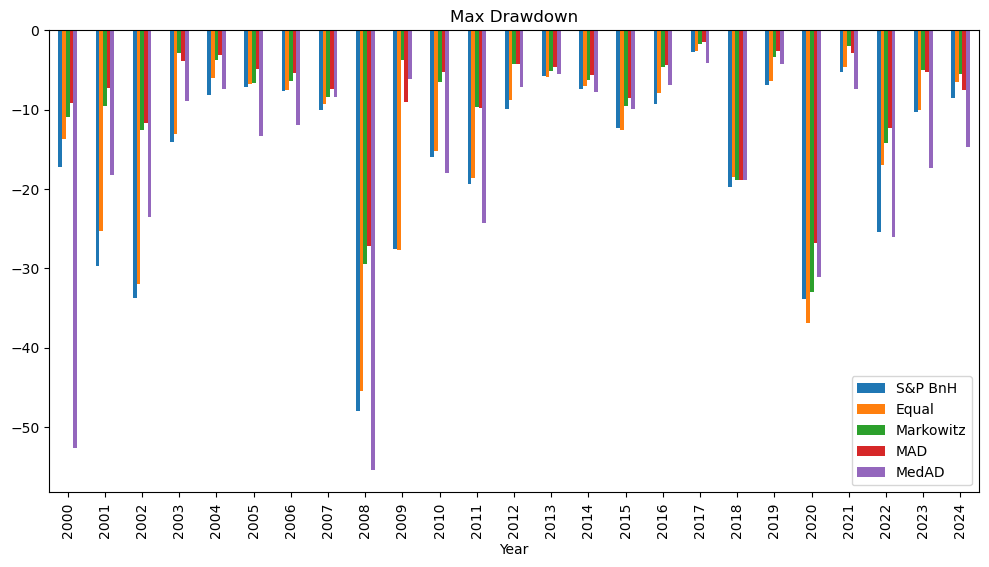

In [7]:
for stat in stats_used:
    stats = {}

    for portfolio in portfolios.keys():
        stats[portfolio] = stats_collector[portfolio][stat]
    stats = pd.DataFrame(stats)
    stats.plot.bar(figsize=(12, 6))
    plt.title(stat)
    plt.legend()
    plt.show()
    plt.close()

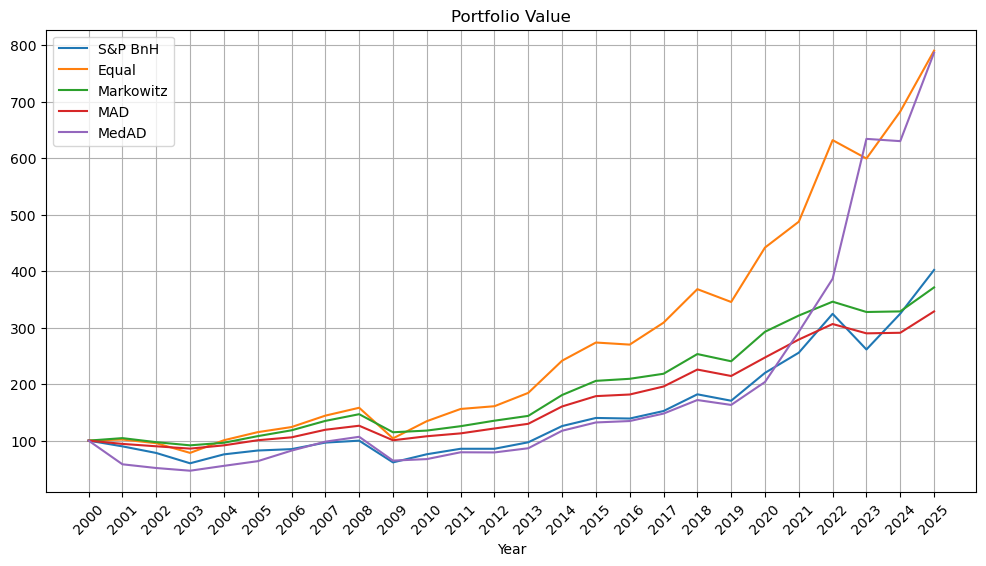

In [8]:
stat = "Annual Return"
stats = {}

for portfolio in portfolios.keys():
    stats[portfolio] = np.cumprod(stats_collector[portfolio][stat] / 100 + 1) * 100
stats = pd.DataFrame(stats)
stats.index = stats.index + 1
stats.loc[2000] = [100] * len(portfolios.keys())
stats = stats.sort_index()
stats.plot.line(figsize=(12, 6))
plt.xticks(stats.index, rotation=45)
plt.grid()
plt.title("Portfolio Value")
plt.legend()
plt.show()
plt.close()

In [9]:
stats

,S&P BnH,Equal,Markowitz,MAD,MedAD
Year,,,,,
2000,100.000000,100.000000,100.000000,100.000000,100.000000
2001,89.860000,101.990000,104.430000,94.190000,58.120000
2002,78.142256,95.421844,97.234773,89.970288,51.517568
2003,59.880411,78.293623,91.672944,85.858646,46.741889
2004,75.676863,100.662111,96.229089,91.645519,55.356420
2005,82.480213,114.996396,107.920924,100.681767,63.637740
2006,84.954620,124.023613,118.259748,105.836673,82.302689
2007,96.525439,144.214657,134.922547,119.235596,98.170648
2008,99.932787,158.145793,146.755254,126.342037,106.780213
